# 2. Accelerometer on the stone: does the strike force affect the timbre?

During the session of 19 October 2025 a second phone **resting on the stone** recorded the linear acceleration with
phyphox (15 records, 14:01–15:15) while the iPhone recorded the sound. This notebook:

1. reads the accelerometer records and synchronises them with each WAV file;
2. assigns to each strike (notebook 01) the acceleration peak it produced;
3. checks whether stronger strikes sound different within the same zone (how much of the variation within a zone is
   due to the hand-held strike?).

**Inputs:** phyphox XML records, `intermediate/strikes.csv` and `intermediate/features.csv` (notebook 01).
**Outputs:** `intermediate/strikes_with_acceleration.csv`, `tables/t02_force_vs_timbre.csv`.

> **Sensor limitation.** The accelerometer samples at 201 Hz: it only sees vibrations below ~100 Hz. It does not
> measure the modes of the stone (385–1938 Hz) or the shape of the strike, which lasts a few milliseconds; its peak is
> an **indirect and noisy** measure of the strike strength.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # folder with config.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.4})
pd.set_option("display.precision", 2)

import re, glob, datetime as dt
from scipy import stats
import seaborn as sns
TZ = dt.timezone(dt.timedelta(hours=-5))   # Peru time

## 2.1 Reading the phyphox records

Each phyphox `.xml` file stores the data in the `init` attribute of its containers (`acc_time`, `acc`) and the start
time in Unix milliseconds (`systemTime`).

In [2]:
def container(s, name):
    m = re.search(r'<container[^>]*init="([^"]*)"[^>]*>' + re.escape(name) + '</container>', s)
    return np.array(m.group(1).split(','), float)

records = {}
for f in glob.glob(str(C.ACCELEROMETER / "*.xml")):
    s = open(f, encoding="utf8").read()
    t0 = int(re.search(r'systemTime="(\d+)"', s).group(1)) / 1000
    t, a = container(s, "acc_time"), container(s, "acc")
    if t0 in records and len(records[t0][1]) >= len(t):
        continue
    records[t0] = (Path(f).name, t, a)

table = pd.DataFrame([{"file": n, "start": dt.datetime.fromtimestamp(t0, TZ).strftime("%H:%M:%S"),
                       "duration_s": t[-1], "fs_Hz": 1 / np.median(np.diff(t))}
                      for t0, (n, t, a) in sorted(records.items())])
print(f"{len(table)} distinct records")
table.round(1)

15 distinct records


,file,start,duration_s,fs_Hz
0,S2_acc_20251019-140124_phyphox27.xml,14:01:24,127.3,200.7
1,S2_acc_20251019-140349_phyphox26.xml,14:03:49,129.1,200.7
2,S2_acc_20251019-140616_phyphox25.xml,14:06:16,120.3,200.7
3,S2_acc_20251019-140918_phyphox23.xml,14:09:18,130.2,200.7
4,S2_acc_20251019-141755_phyphox22.xml,14:17:55,90.8,200.6
5,S2_acc_20251019-142011_phyphox21.xml,14:20:11,115.5,200.6
6,S2_acc_20251019-143801_phyphox06.xml,14:38:01,69.1,200.7
7,S2_acc_20251019-144001_phyphox08.xml,14:40:01,72.7,200.7
8,S2_acc_20251019-144302_phyphox07.xml,14:43:02,64.6,200.7
9,S2_acc_20251019-150157_phyphox02.xml,15:01:57,63.2,200.7


## 2.2 Time of each strike in the audio

The **absolute time** of the peak of each strike (notebook 01) is the start time of the WAV file (in its name) plus
the position of the peak within the file.

In [3]:
def t_wav(name):
    return dt.datetime(2025, 10, 19, int(name[9:11]), int(name[11:13]), int(name[13:15]), tzinfo=TZ).timestamp()

strikes = pd.read_csv(C.INTERMEDIATE / "strikes.csv")
strikes["t_abs"] = [t_wav(w) + i / C.FS for w, i in zip(strikes.file, strikes.i_peak)]
print(len(strikes), "strikes;", strikes.file.nunique(), "WAV files")

613 strikes; 18 WAV files


## 2.3 Clock synchronisation

The two phones have different clocks. For each WAV file the accelerometer record that started closest is taken, and
the offset (between −3 and +3 s, in 10 ms steps) that matches the most audio strikes with accelerometer pulses (peak >
median + 8 robust standard deviations of the noise) is searched for.

In [4]:
def offset(sel, t, a):
    noise = 1.4826 * np.median(np.abs(a - np.median(a))); base = np.median(a)
    best = (-1, 0.0)
    for o in np.arange(-3, 3, 0.01):
        n = sum(a[max(0, np.searchsorted(t, u + o) - 4): np.searchsorted(t, u + o) + 6].max(initial=0) > base + 8 * noise for u in sel)
        best = max(best, (n, o))
    return best

pairs = []
for w in strikes.file.unique():
    t0 = min(records, key=lambda k: abs(k - t_wav(w)))
    n_ok, o = offset(strikes.loc[strikes.file == w, "t_abs"].values - t0, *records[t0][1:])
    pairs.append({"wav": w, "accelerometer": records[t0][0], "t0": t0, "offset_s": o,
                  "strikes": (strikes.file == w).sum(), "detected": n_ok})
pairs = pd.DataFrame(pairs)
pairs["no_record"] = pairs.detected < 0.5 * pairs.strikes   # no accelerometer record covers this WAV file
pairs["% detected"] = (100 * pairs.detected / pairs.strikes).round(0)
pairs.drop(columns="t0").round(2)

,wav,accelerometer,offset_s,strikes,detected,no_record,% detected
0,20251019-135332.wav,S2_acc_20251019-140124_phyphox27.xml,2.99,47,0,True,0.0
1,20251019-135632.wav,S2_acc_20251019-140124_phyphox27.xml,2.99,50,0,True,0.0
2,20251019-135829.wav,S2_acc_20251019-140124_phyphox27.xml,2.99,30,0,True,0.0
3,20251019-140152.wav,S2_acc_20251019-140124_phyphox27.xml,0.96,50,45,False,90.0
4,20251019-140412.wav,S2_acc_20251019-140349_phyphox26.xml,1.19,50,48,False,96.0
5,20251019-140629.wav,S2_acc_20251019-140616_phyphox25.xml,1.07,51,40,False,78.0
6,20251019-140944.wav,S2_acc_20251019-140918_phyphox23.xml,1.00,45,24,False,53.0
7,20251019-141757.wav,S2_acc_20251019-141755_phyphox22.xml,0.91,39,39,False,100.0
8,20251019-142014.wav,S2_acc_20251019-142011_phyphox21.xml,1.42,44,44,False,100.0
9,20251019-151007.wav,S2_acc_20251019-151003_phyphox15.xml,1.43,19,19,False,100.0


The offset is almost constant (about +1 s) in all pairs that have an accelerometer record, which confirms that the
synchronisation is correct: the two phones recorded the same strikes. The first three recordings were made before the
accelerometer was started.

## 2.4 Acceleration peak of each strike
In a window from −30 to +50 ms around the synchronised time, the maximum of |a| minus the preceding baseline is taken.

Strikes with a clear pulse (SNR > 8): 454 of 613
Variation of the strike strength within each zone and file: median CV = 13%


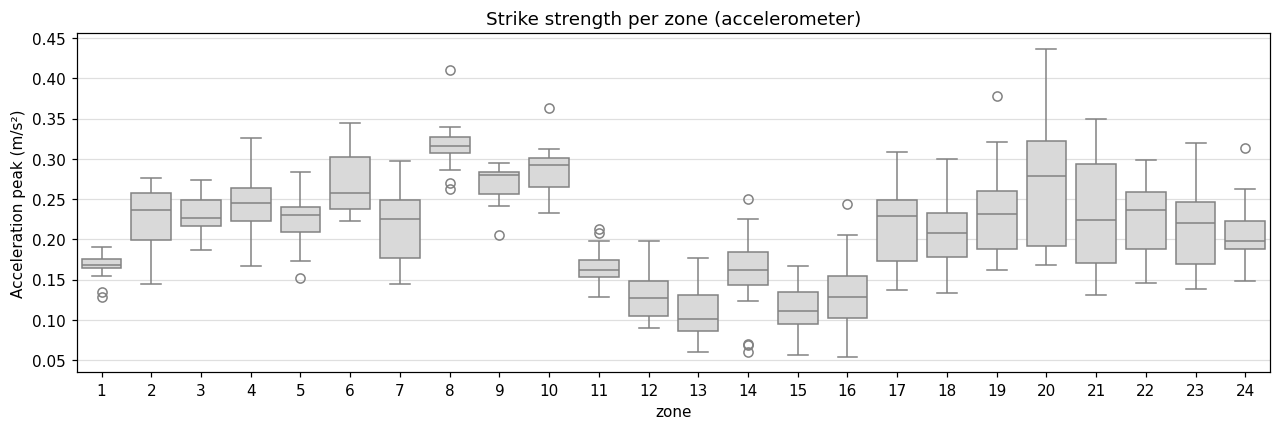

In [5]:
P = pairs.set_index("wav")
def peak(r):
    t0 = P.loc[r.file, "t0"]; _, t, a = records[t0]
    i = np.searchsorted(t, r.t_abs - t0 + P.loc[r.file, "offset_s"])
    base = np.median(a[max(0, i - 60): max(1, i - 10)])
    noise = 1.4826 * np.median(np.abs(a[max(0, i - 60): max(1, i - 10)] - base))
    return pd.Series({"acc_peak": a[max(0, i - 6): i + 10].max() - base, "acc_snr": (a[max(0, i - 6): i + 10].max() - base) / max(noise, 1e-6)})
strikes[["acc_peak", "acc_snr"]] = strikes.apply(peak, axis=1)
strikes.loc[strikes.file.isin(pairs.wav[pairs.no_record]), ["acc_peak", "acc_snr"]] = np.nan
feat = pd.read_csv(C.INTERMEDIATE / "features.csv").drop(columns=["file", "t_s", "set"])
d = strikes.merge(feat, on=["zone", "strike"])
d.to_csv(C.INTERMEDIATE / "strikes_with_acceleration.csv", index=False)
print(f"Strikes with a clear pulse (SNR > 8): {(d.acc_snr > 8).sum()} of {len(d)}")
cv = (d.groupby(["zone", "file"]).acc_peak.std() / d.groupby(["zone", "file"]).acc_peak.mean())
print(f"Variation of the strike strength within each zone and file: median CV = {cv.median():.0%}")
plt.figure(figsize=(14, 4))
sns.boxplot(x="zone", y="acc_peak", data=d, color="0.85")
plt.ylabel("Acceleration peak (m/s²)"); plt.title("Strike strength per zone (accelerometer)")
plt.savefig(C.FIGURES / "fig02a_strike_strength.png", dpi=150, bbox_inches="tight"); plt.show()

## 2.5 Do stronger strikes sound different?

To separate the effect of force from the effect of the zone, each variable is **centred on its zone and file** (the
group mean is subtracted), so that only the variation between strikes of the same zone remains. The Spearman
correlation (robust to outliers) between the logarithm of the acceleration peak and each spectral feature is used.

The strikes with a clear pulse of the **characterisation set** (notebook 01, section 1.3) are used.

In [6]:
d2 = d[(d.acc_snr > 8) & (d.set == "characterisation")].copy()
d2["log_acc"] = np.log10(d2.acc_peak)
group = ["zone", "file"]
res = []
for c, name in [("spectral_centroid", "Centroid"), ("spectral_bandwidth", "Bandwidth"),
                ("mfcc_0", "MFCC0 (energy)"), ("mfcc_1", "MFCC1")]:
    x = d2.log_acc - d2.groupby(group).log_acc.transform("mean")
    y = d2[c] - d2.groupby(group)[c].transform("mean")
    rho, p = stats.spearmanr(x, y)
    res.append({"strikes": len(d2), "recordings": d2.file.nunique(), "feature": name,
                "spearman_rho": rho, "p": p, "linear_R2": np.corrcoef(x, y)[0, 1] ** 2})
res = pd.DataFrame(res)
res.to_csv(C.TABLES / "t02_force_vs_timbre.csv", index=False)
res.style.format({"spearman_rho": "{:+.2f}", "p": "{:.3f}", "linear_R2": "{:.1%}"}).hide(axis="index")

strikes,recordings,feature,spearman_rho,p,linear_R2
352,11,Centroid,+0.06,0.237,1.2%
352,11,Bandwidth,-0.10,0.061,0.3%
352,11,MFCC0 (energy),-0.01,0.906,0.0%
352,11,MFCC1,-0.01,0.883,0.1%


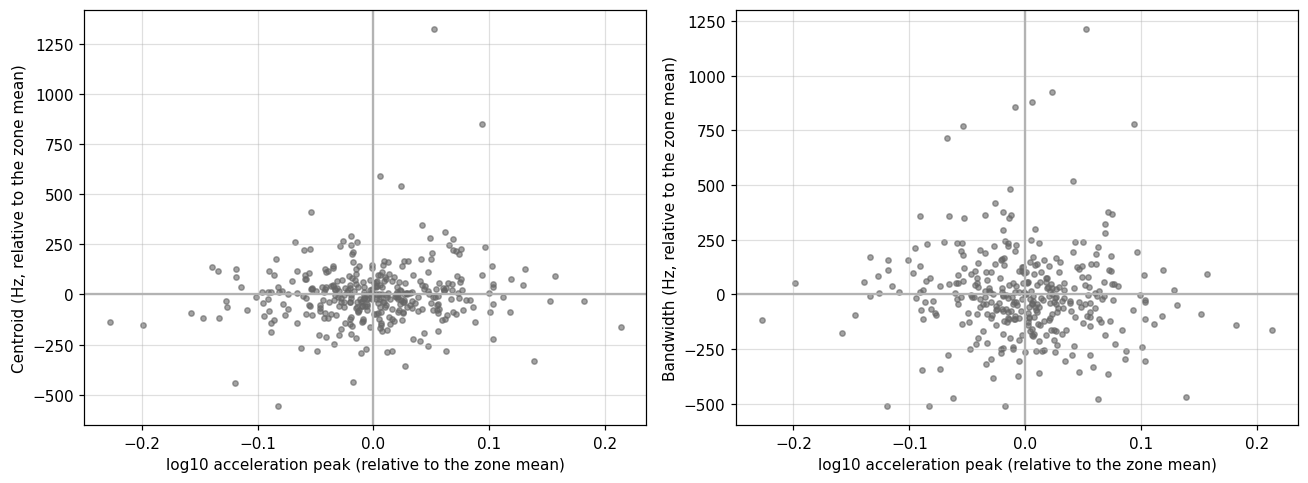

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, c, name in [(ax[0], "spectral_centroid", "Centroid (Hz, relative to the zone mean)"),
                   (ax[1], "spectral_bandwidth", "Bandwidth (Hz, relative to the zone mean)")]:
    x = d2.log_acc - d2.groupby(group).log_acc.transform("mean")
    y = d2[c] - d2.groupby(group)[c].transform("mean")
    a.scatter(x, y, s=12, color="0.4", alpha=.6); a.axhline(0, color="0.7"); a.axvline(0, color="0.7")
    a.set_xlabel("log10 acceleration peak (relative to the zone mean)"); a.set_ylabel(name)
plt.tight_layout(); plt.savefig(C.FIGURES / "fig02b_force_vs_timbre.png", dpi=150, bbox_inches="tight"); plt.show()

## Conclusion

* The accelerometer recorded the same strikes as the audio, with a stable clock offset of ~1 s.
* The strength of the hand-held strikes was **fairly uniform** within each zone (coefficient of variation of about
  13 %).
* The strike strength explains **a very small fraction** of the variation of the timbre within a zone (column
  `linear_R2` of the table).
* The strike-to-strike variation (notebook 05) is therefore **not mainly due to the force**; it more probably comes
  from the exact point and angle of the strike within the zone.

**Caution:** at 201 Hz the acceleration peak is an indirect measure of force. The result is reported as "no evidence
of an important effect of the strike strength", not as proof of its absence.